Atividade 4 — IDHM por Unidade da Federação

A `Tabela4.csv` usa `;` como separador e vírgula como decimal. A primeira linha é o título da tabela, então o cabeçalho de verdade está na segunda linha.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

1. Abrir o CSV

In [2]:
path = "Tabela4.csv"
df = pd.read_csv(path, sep=";", decimal=",", encoding="latin-1", header=1)
df.head()

,Sigla,Código,Estado,1991,2000,2010,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,AC,12,Acre,0.402,0.517,0.663,0.705,0.709,0.719,0.719,0.723,0.711,0.731,0.738,0.736,0.702,0.732,0.740,0.754
1,AL,27,Alagoas,0.370,0.471,0.631,0.657,0.653,0.670,0.669,0.680,0.682,0.694,0.693,0.694,0.691,0.722,0.739,0.746
2,AM,13,Amazonas,0.430,0.515,0.674,0.706,0.717,0.720,0.724,0.723,0.743,0.732,0.739,0.725,0.700,0.757,0.764,0.767
3,AP,16,Amapá,0.472,0.577,0.708,0.709,0.735,0.726,0.728,0.732,0.731,0.737,0.732,0.707,0.681,0.743,0.767,0.759
4,BA,29,Bahia,0.386,0.512,0.660,0.684,0.686,0.700,0.708,0.708,0.715,0.714,0.723,0.726,0.698,0.734,0.740,0.759


2. Limpar colunas vazias

O título da planilha deixa colunas sem nome quando o arquivo é lido pela primeira linha. Com o cabeçalho na segunda linha elas não entram, mas a limpeza fica no código mesmo assim.

In [3]:
df = df.dropna(axis=1, how="all")
df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]
df

,Sigla,Código,Estado,1991,2000,2010,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,AC,12,Acre,0.402,0.517,0.663,0.705,0.709,0.719,0.719,0.723,0.711,0.731,0.738,0.736,0.702,0.732,0.740,0.754
1,AL,27,Alagoas,0.370,0.471,0.631,0.657,0.653,0.670,0.669,0.680,0.682,0.694,0.693,0.694,0.691,0.722,0.739,0.746
2,AM,13,Amazonas,0.430,0.515,0.674,0.706,0.717,0.720,0.724,0.723,0.743,0.732,0.739,0.725,0.700,0.757,0.764,0.767
3,AP,16,Amapá,0.472,0.577,0.708,0.709,0.735,0.726,0.728,0.732,0.731,0.737,0.732,0.707,0.681,0.743,0.767,0.759
4,BA,29,Bahia,0.386,0.512,0.660,0.684,0.686,0.700,0.708,0.708,0.715,0.714,0.723,0.726,0.698,0.734,0.740,0.759
5,CE,23,Ceará,0.405,0.541,0.682,0.709,0.712,0.717,0.723,0.727,0.737,0.746,0.754,0.753,0.740,0.759,0.773,0.773
6,DF,53,Distrito Federal,0.616,0.725,0.824,0.824,0.834,0.834,0.833,0.842,0.842,0.845,0.860,0.837,0.823,0.867,0.870,0.866
7,ES,32,Espírito Santo,0.505,0.640,0.740,0.747,0.755,0.763,0.766,0.766,0.769,0.776,0.780,0.773,0.754,0.782,0.803,0.804
8,GO,52,Goiás,0.487,0.615,0.735,0.744,0.753,0.759,0.758,0.765,0.770,0.776,0.780,0.777,0.755,0.797,0.809,0.815
9,MA,21,Maranhão,0.357,0.476,0.639,0.669,0.682,0.683,0.690,0.698,0.704,0.706,0.715,0.715,0.701,0.730,0.740,0.745


3. Estados ordenados pelo maior IDH em 2024

In [4]:
anos = [c for c in df.columns if str(c).isdigit()]
for col in anos:
    df[col] = pd.to_numeric(df[col], errors="coerce")

ordem_2024 = df.sort_values("2024", ascending=False).reset_index(drop=True)
ordem_2024[["Sigla", "Estado", "2024"]]

,Sigla,Estado,2024
0,DF,Distrito Federal,0.866
1,SP,São Paulo,0.838
2,SC,Santa Catarina,0.833
3,PR,Paraná,0.822
4,RJ,Rio de Janeiro,0.819
5,RS,Rio Grande do Sul,0.818
6,GO,Goiás,0.815
7,MT,Mato Grosso,0.812
8,MG,Minas Gerais,0.809
9,ES,Espírito Santo,0.804


O Distrito Federal tem o maior IDH em 2024 (0,866). Em seguida vêm São Paulo (0,838) e Santa Catarina (0,833). O menor é o Maranhão (0,745).

4. Qual estado teve a maior melhora de IDH entre 1991 e 2024?

In [5]:
melhora = df[["Sigla", "Estado", "1991", "2024"]].copy()
melhora["melhora"] = (melhora["2024"] - melhora["1991"]).round(3)
melhora = melhora.sort_values("melhora", ascending=False).reset_index(drop=True)
melhora

,Sigla,Estado,1991,2024,melhora
0,TO,Tocantins,0.369,0.797,0.428
1,PI,Piauí,0.362,0.764,0.402
2,MA,Maranhão,0.357,0.745,0.388
3,RO,Rondônia,0.407,0.786,0.379
4,PB,Paraíba,0.382,0.760,0.378
5,AL,Alagoas,0.370,0.746,0.376
6,BA,Bahia,0.386,0.759,0.373
7,CE,Ceará,0.405,0.773,0.368
8,MT,Mato Grosso,0.449,0.812,0.363
9,SE,Sergipe,0.408,0.761,0.353


Tocantins teve a maior melhora: de 0,369 em 1991 para 0,797 em 2024, um ganho de 0,428. Piauí (+0,402) e Maranhão (+0,388) vêm logo atrás.

5. Existe algum estado em que o IDH piorou?

In [6]:
piorou_no_periodo = melhora[melhora["2024"] < melhora["1991"]]
print(f"Estados com IDH 2024 menor que em 1991: {len(piorou_no_periodo)}")

quedas = []
for _, row in df.iterrows():
    anterior = None
    for ano in anos:
        valor = row[ano]
        if anterior is not None and valor < anterior:
            quedas.append(row["Sigla"])
            break
        anterior = valor
print(f"Estados com alguma queda de um ano para o outro: {len(quedas)} de {len(df)}")

caiu_no_ultimo_ano = df.loc[df["2024"] < df["2023"], ["Sigla", "Estado", "2023", "2024"]]
caiu_no_ultimo_ano

Estados com IDH 2024 menor que em 1991: 0
Estados com alguma queda de um ano para o outro: 27 de 27


,Sigla,Estado,2023,2024
3,AP,Amapá,0.767,0.759
6,DF,Distrito Federal,0.870,0.866


De 1991 para 2024, não: nenhum estado terminou abaixo do ponto de partida.

No meio da série, sim. Os 27 estados tiveram pelo menos uma queda de um ano para o outro. A queda mais comum é de 2020 para 2021. De 2023 para 2024, só Amapá (0,767 para 0,759) e o Distrito Federal (0,870 para 0,866) caíram.

5. Passar a tabela do formato largo para o formato longo

In [7]:
anos = [c for c in df.columns if str(c).isdigit()]
print(anos)

id_vars = [c for c in df.columns if c not in anos]
df_longo = df.melt(
    id_vars=id_vars,
    value_vars=anos,
    var_name="Ano",
    value_name="IDH",
)
df_longo["Ano"] = df_longo["Ano"].astype(int)
df_longo["IDH"] = pd.to_numeric(df_longo["IDH"], errors="coerce")
df_longo.head()

['1991', '2000', '2010', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']


,Sigla,Código,Estado,Ano,IDH
0,AC,12,Acre,1991,0.402
1,AL,27,Alagoas,1991,0.370
2,AM,13,Amazonas,1991,0.430
3,AP,16,Amapá,1991,0.472
4,BA,29,Bahia,1991,0.386


6. Plotar apenas Minas Gerais

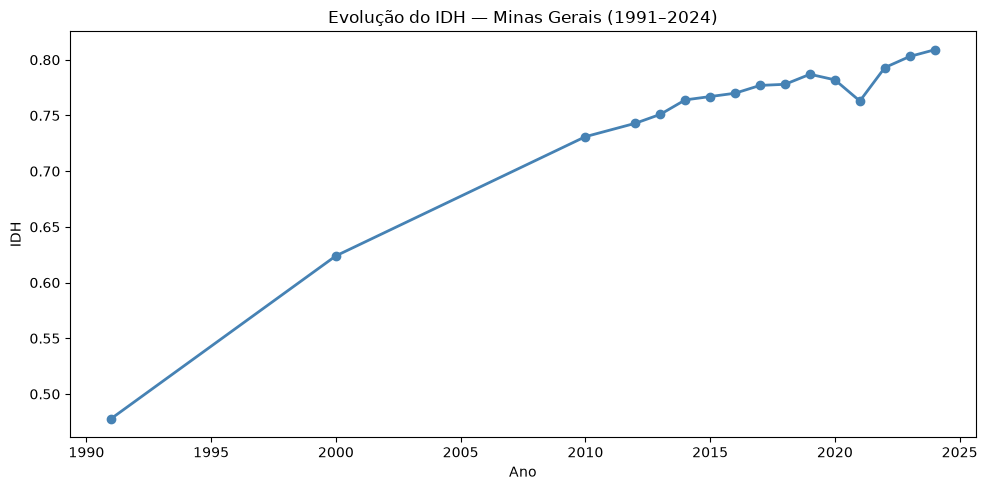

In [8]:
mg = df_longo[df_longo["Sigla"] == "MG"].sort_values("Ano")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(mg["Ano"], mg["IDH"], marker="o", linewidth=2, color="steelblue")
ax.set_title("Evolução do IDH — Minas Gerais (1991–2024)")
ax.set_xlabel("Ano")
ax.set_ylabel("IDH")
fig.tight_layout()
plt.show()

7. Evolução do IDH de cada estado

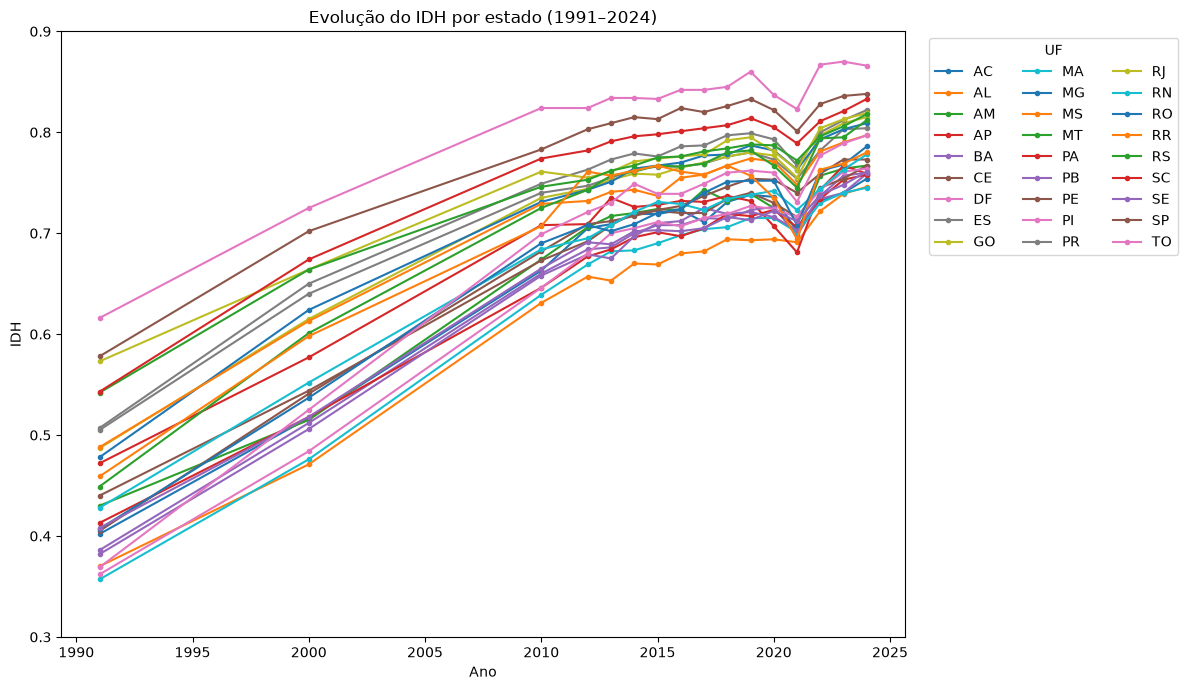

In [9]:
fig, ax = plt.subplots(figsize=(12, 7))

for sigla, grupo in df_longo.groupby("Sigla"):
    grupo = grupo.sort_values("Ano")
    ax.plot(grupo["Ano"], grupo["IDH"], marker="o", markersize=3, linewidth=1.5, label=sigla)

ax.set_title("Evolução do IDH por estado (1991–2024)")
ax.set_xlabel("Ano")
ax.set_ylabel("IDH")
ax.set_ylim(0.3, 0.9)
ax.legend(ncol=3, bbox_to_anchor=(1.02, 1), loc="upper left", title="UF")
fig.tight_layout()
plt.show()